## Trajectory - X

In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

In [3]:
top_10_genes = ['YOD1', 'SGK1', 'PARD6B', 'SMAD7', 'KLF6', 'KLF10', 'CEBPD', 'PLK2', 'ADM', 'GRPEL2']
subset_top10 = hdata[top_10_genes, :]   

In [4]:
# top_10_traj = subset_top10.get_highly_dynamic_trajectories(n=10)
top_10_traj = [884, 194, 157, 797, 926, 160, 252, 709, 349, 866]

### KMeans trajectory

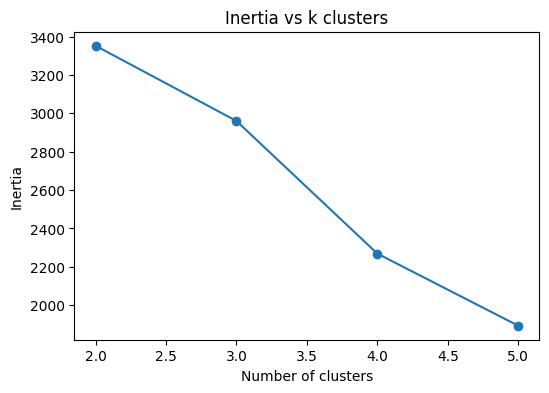

In [5]:
hdata.find_kmeans_k(
    data = subset_top10,
    key = "X",
    kind = "trajectory",
    trajectory_id = top_10_traj,
)

In [6]:
hdata.cluster_kmeans(
        data = subset_top10,
        key = "X",
        kind = "trajectory",
        trajectory_id = top_10_traj,
        k = 4
    )

Cluster "kmeans_k4_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: []
  clusters: ['kmeans_k4_trajectory']
  embeddings: []
  trajectories: Yes

In [7]:
# view clustering results

hdata.clusters['kmeans_k4_trajectory']

traj_884    1
traj_194    3
traj_157    2
traj_797    2
traj_926    1
traj_160    0
traj_252    1
traj_709    2
traj_349    2
traj_866    3
Name: kmeans_k4_trajectory, dtype: int32

In [8]:
hdata.reduce_PCA(
    data = subset_top10,
    key = "X",
    kind = "trajectory",
    trajectory_id = top_10_traj,
)

PCA embedding "pca_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: []
  clusters: ['kmeans_k4_trajectory']
  embeddings: ['pca_trajectory']
  trajectories: Yes

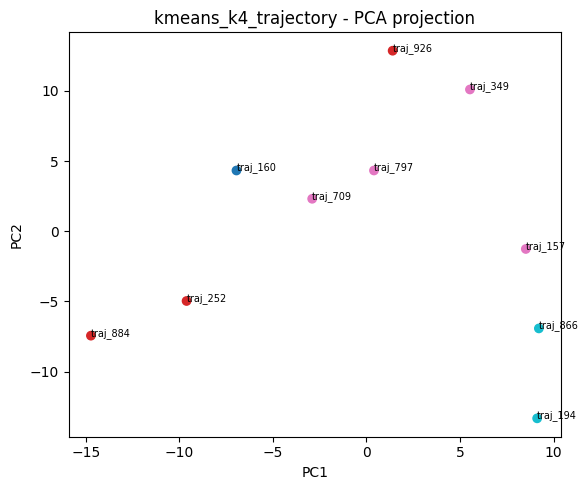

In [10]:
c1 = hdata.clusters["kmeans_k4_trajectory"]
e1 = hdata.embeddings["pca_trajectory"]

hda.visualize.scatter(
    cluster=c1,
    embedding=e1,
    reduction="PCA"
)

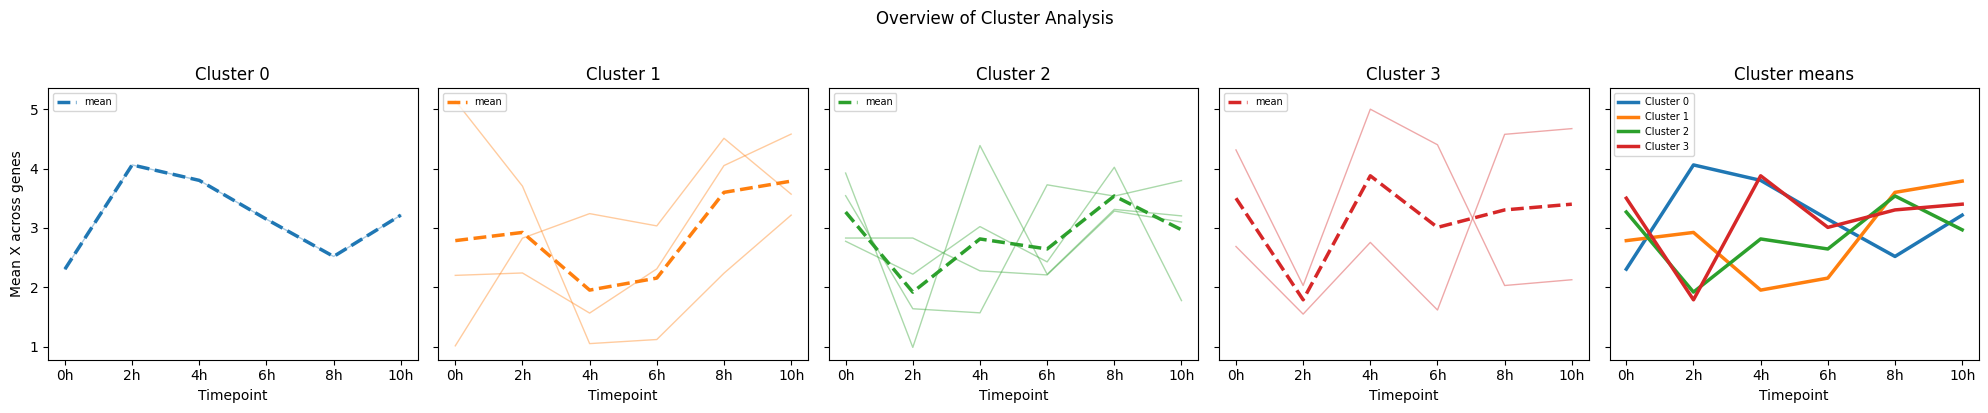

In [11]:
hda.visualize.line(
    data=subset_top10,
    cluster=c1,
    key="X",
    kind="trajectory",
    trajectory_id=top_10_traj
)

### Hierarchical traj

In [12]:
hdata.compute_similarity(
    data=subset_top10,
    key="X",
    kind="trajectory",
    trajectory_id=top_10_traj,
    method="correlation"
)

Similarity "correlation_X_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_X_trajectory']
  clusters: ['kmeans_k4_trajectory']
  embeddings: ['pca_trajectory']
  trajectories: Yes

In [13]:
sim1 = hdata.similarities["correlation_X_trajectory"]

hdata.cluster_hierarchical(
        sim = sim1,
        kind = "trajectory",
        k = 4
    )

Cluster "hierarchical_k4_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_X_trajectory']
  clusters: ['kmeans_k4_trajectory', 'hierarchical_k4_trajectory']
  embeddings: ['pca_trajectory']
  trajectories: Yes

In [14]:
hdata.reduce_MDS(
    sim = sim1,
    kind = "trajectory"
)

MDS embedding "mds_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_X_trajectory']
  clusters: ['kmeans_k4_trajectory', 'hierarchical_k4_trajectory']
  embeddings: ['pca_trajectory', 'mds_trajectory']
  trajectories: Yes

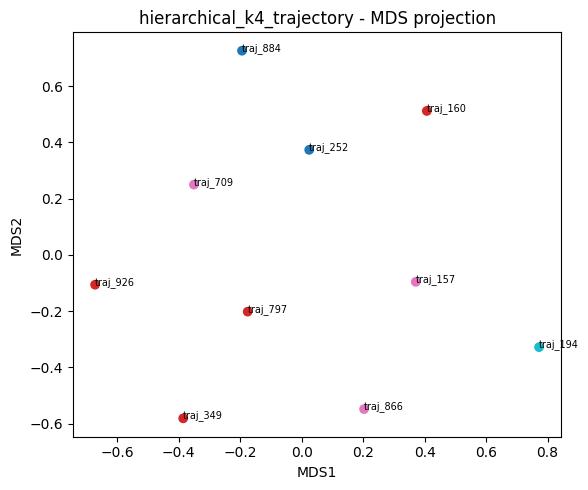

In [15]:
c2 = hdata.clusters["hierarchical_k4_trajectory"]
e2 = hdata.embeddings["mds_trajectory"]

hda.visualize.scatter(
    cluster=c2,
    embedding=e2,
    reduction="MDS"
)

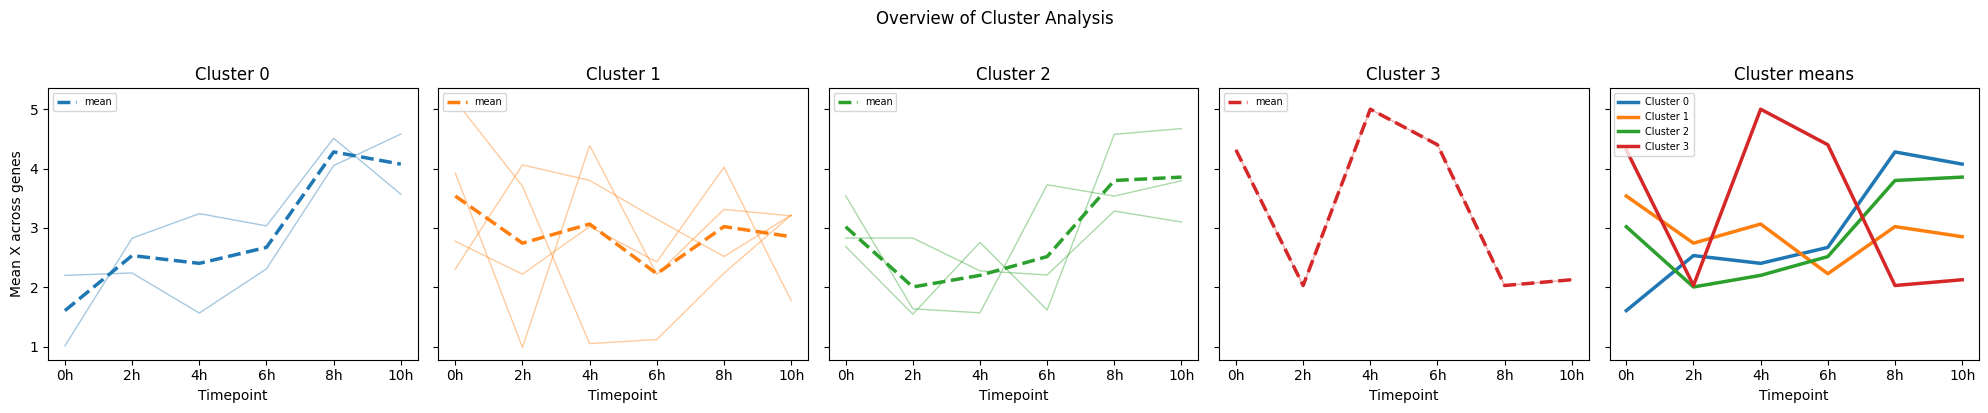

In [16]:
hda.visualize.line(
    data=subset_top10,
    cluster=c2,
    key="X",
    kind="trajectory",
    trajectory_id=top_10_traj
)

### Graph-based clustering trajectory

In [17]:
hdata.cluster_spectral(
        sim = sim1,
        kind = "trajectory",
        k = 4
    )

Cluster "spectral_k4_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_X_trajectory']
  clusters: ['kmeans_k4_trajectory', 'hierarchical_k4_trajectory', 'spectral_k4_trajectory']
  embeddings: ['pca_trajectory', 'mds_trajectory']
  trajectories: Yes

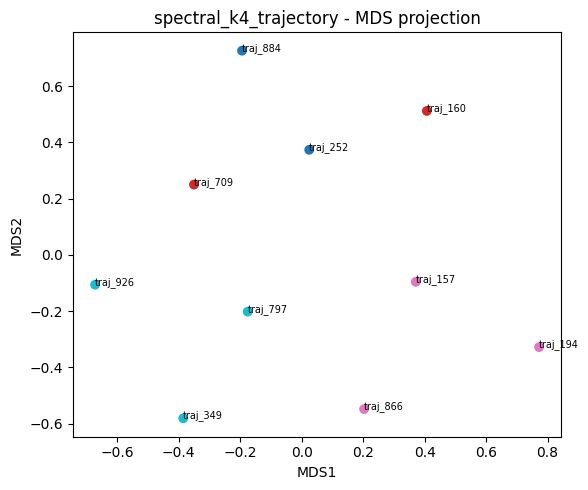

In [18]:
c3 = hdata.clusters["spectral_k4_trajectory"]

hda.visualize.scatter(
    cluster=c3,
    embedding=e2,
    reduction="MDS"
)

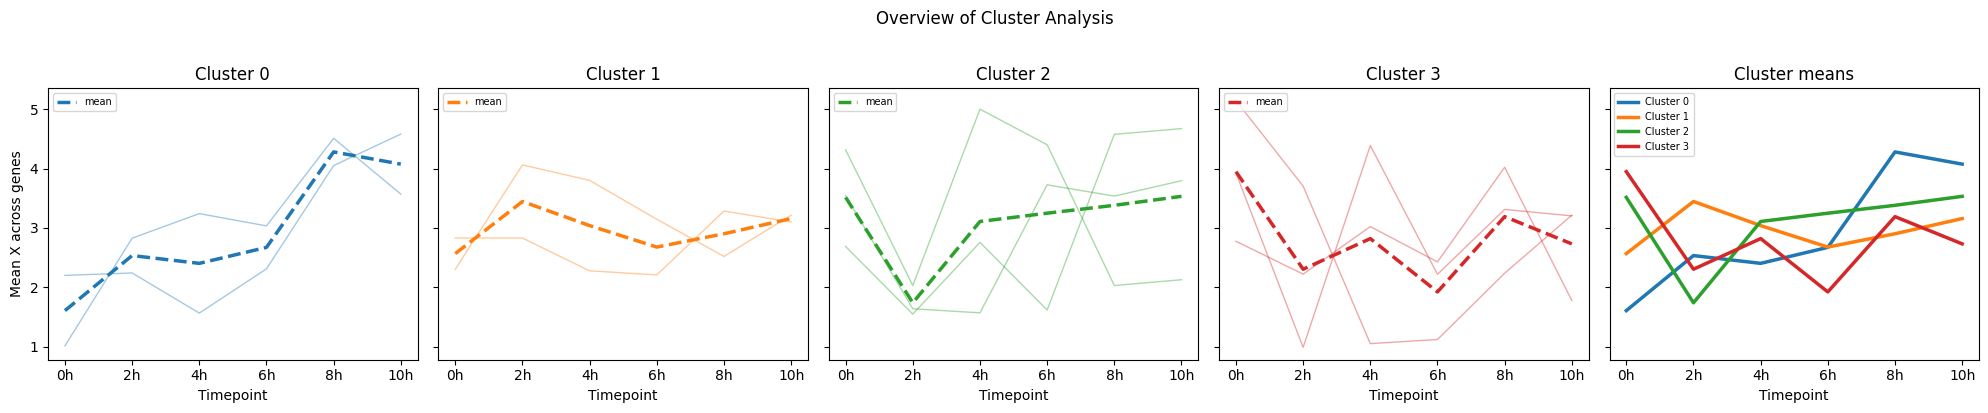

In [19]:
hda.visualize.line(
    data=subset_top10,
    cluster=c3,
    key="X",
    kind="trajectory",
    trajectory_id=top_10_traj
)